# OCT Eye Disease - Complete Testing Notebook

This notebook tests the trained model (`eye_trained_model.keras`) end-to-end.

**Key parameters - must match the training notebook exactly:**
| Parameter | Value |
|---|---|
| Image size | 224 × 224 |
| Color mode | grayscale (1 channel) |
| Normalisation | **inside the model** (`Rescaling(1/255)` layer) - do NOT divide manually |
| Label mode | categorical (one-hot) |
| Class order | alphabetical: `CNV, DME, DRUSEN, NORMAL` |


**bold text** ## 1 · Mount Google Drive & Load Model

In [1]:
# Optional Colab / Kaggle setup.
# Uncomment only when running in a fresh notebook environment.

import os
os.makedirs("/root/.kaggle", exist_ok=True)
!pip install kaggle==1.6.17
!mv kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json
!kaggle datasets download -d anirudhcv/labeled-optical-coherence-tomography-oct
!unzip /content/labeled-optical-coherence-tomography-oct.zip -d /content/

Streaming output truncated to the last 5000 lines.
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-15.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-16.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-18.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-2.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5822041-8.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-582215-6.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-582215-7.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-582215-8.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5823731-1.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5823731-5.jpeg  
  inflating: /content/Dataset - train+val+test/val/NORMAL/NORMAL-5824080-5.jpeg  
  inflating: /content/Dataset - train+val+test/

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import tensorflow as tf
# Where to load the saved model from
MODEL_PATH = "/content/drive/MyDrive/oct_outputs_cnn/eye_trained_model.keras"

model = tf.keras.models.load_model(MODEL_PATH)
model.summary()
print("\nModel loaded successfully.")
print("Input shape expected by model:", model.input_shape)


Model: "oct_grayscale_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oct_augmentation (Sequential)   │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 128)    │             

 Total params: 3,720,302 (14.19 MB)

 Trainable params: 1,239,460 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

 Optimizer params: 2,478,922 (9.46 MB)


Model loaded successfully.
Input shape expected by model: (None, 224, 224, 1)


## 1 · Imports & Configuration

In [ ]:
import os
import json
import pickle
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

import tensorflow as tf
from sklearn.metrics import (
    classification_report, confusion_matrix,
    balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
    roc_curve, auc, roc_auc_score, precision_recall_curve,
)
from sklearn.preprocessing import label_binarize

sns.set_theme(style="whitegrid")

# - Must match training notebook exactly ──────────────────────────────────────
IMG_SIZE    = (224, 224)       # training used 224×224, NOT 128×128
COLOR_MODE  = "grayscale"      # training used grayscale (1 channel), NOT rgb
BATCH_SIZE  = 8
SEED        = 42
AUTOTUNE    = tf.data.AUTOTUNE

DATASET_ROOT = "/content/Dataset - train+val+test"
TRAIN_DIR    = os.path.join(DATASET_ROOT, "train")
VAL_DIR      = os.path.join(DATASET_ROOT, "val")
TEST_DIR     = os.path.join(DATASET_ROOT, "test")


print("TensorFlow version:", tf.__version__)
print(f"Image size: {IMG_SIZE}")
print(f"Color mode: {COLOR_MODE}")


TensorFlow version: 2.20.0
Image size: (224, 224)
Color mode: grayscale


## 3 · Load Datasets

Datasets are loaded with **exactly the same parameters as in training**:
- `color_mode="grayscale"` → tensors have shape `(batch, 224, 224, 1)`
- `label_mode="categorical"` → one-hot labels
- `shuffle=False` for val/test so ground-truth order is preserved
- **No manual rescaling** - the model's first layer (`Rescaling(1/255)`) handles it


In [5]:
def load_dataset(split_dir, shuffle):
    ds = tf.keras.utils.image_dataset_from_directory(
        split_dir,
        labels="inferred",
        label_mode="categorical",
        color_mode=COLOR_MODE,       # grayscale → (H, W, 1)
        batch_size=BATCH_SIZE,
        image_size=IMG_SIZE,         # 224×224
        shuffle=shuffle,
        seed=SEED if shuffle else None,
        interpolation="bilinear",
    )
    # Read class_names BEFORE .prefetch() - PrefetchDataset hides the attribute
    class_names = ds.class_names
    return ds.prefetch(AUTOTUNE), class_names


training_set, class_names = load_dataset(TRAIN_DIR, shuffle=True)
validation_set, _         = load_dataset(VAL_DIR,   shuffle=False)
test_set, _               = load_dataset(TEST_DIR,  shuffle=False)

num_classes = len(class_names)

print("Classes (alphabetical order):", class_names)
print("Number of classes:", num_classes)
print("Training element spec:", training_set.element_spec)


Found 76515 files belonging to 4 classes.
Found 21861 files belonging to 4 classes.
Found 10933 files belonging to 4 classes.
Classes (alphabetical order): ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Number of classes: 4
Training element spec: (TensorSpec(shape=(None, 224, 224, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))


## 4 · Quick Sanity Check

In [6]:
sample_images, sample_labels = next(iter(test_set))

print("Batch images shape:", sample_images.shape)   # (8, 224, 224, 1)
print("Batch labels shape:", sample_labels.shape)   # (8, 4)
print("Pixel dtype:", sample_images.dtype)
print("Raw pixel range: [{:.0f}, {:.0f}]".format(
    float(tf.reduce_min(sample_images)),
    float(tf.reduce_max(sample_images)),
))
print()
# Verify model produces sensible output
dummy_out = model(sample_images, training=False)
print("Model output shape:", dummy_out.shape)        # (8, 4)
print("Prob sum per sample (should be ~1.0):",
      np.round(np.sum(dummy_out.numpy(), axis=1), 4))


Batch images shape: (8, 224, 224, 1)
Batch labels shape: (8, 4)
Pixel dtype: <dtype: 'float32'>
Raw pixel range: [0, 255]

Model output shape: (8, 4)
Prob sum per sample (should be ~1.0): [1. 1. 1. 1. 1. 1. 1. 1.]


## 5 · Medical Diagnostic Grid - 4 × 4 Sample Visualisation

16 representative OCT images (4 per class) in a compact clinical-style grid.

Each panel shows:
- **True-label badge** (top-left) and **sample index** (top-right)
- **Prediction verdict** (bottom overlay — ✓ correct, ✗ wrong) with confidence %
- **Per-class probability bars** flush to image width, zero gap between image and bars


Loaded 20 sample paths
Label distribution: {'CNV': 5, 'DME': 5, 'DRUSEN': 5, 'NORMAL': 5}


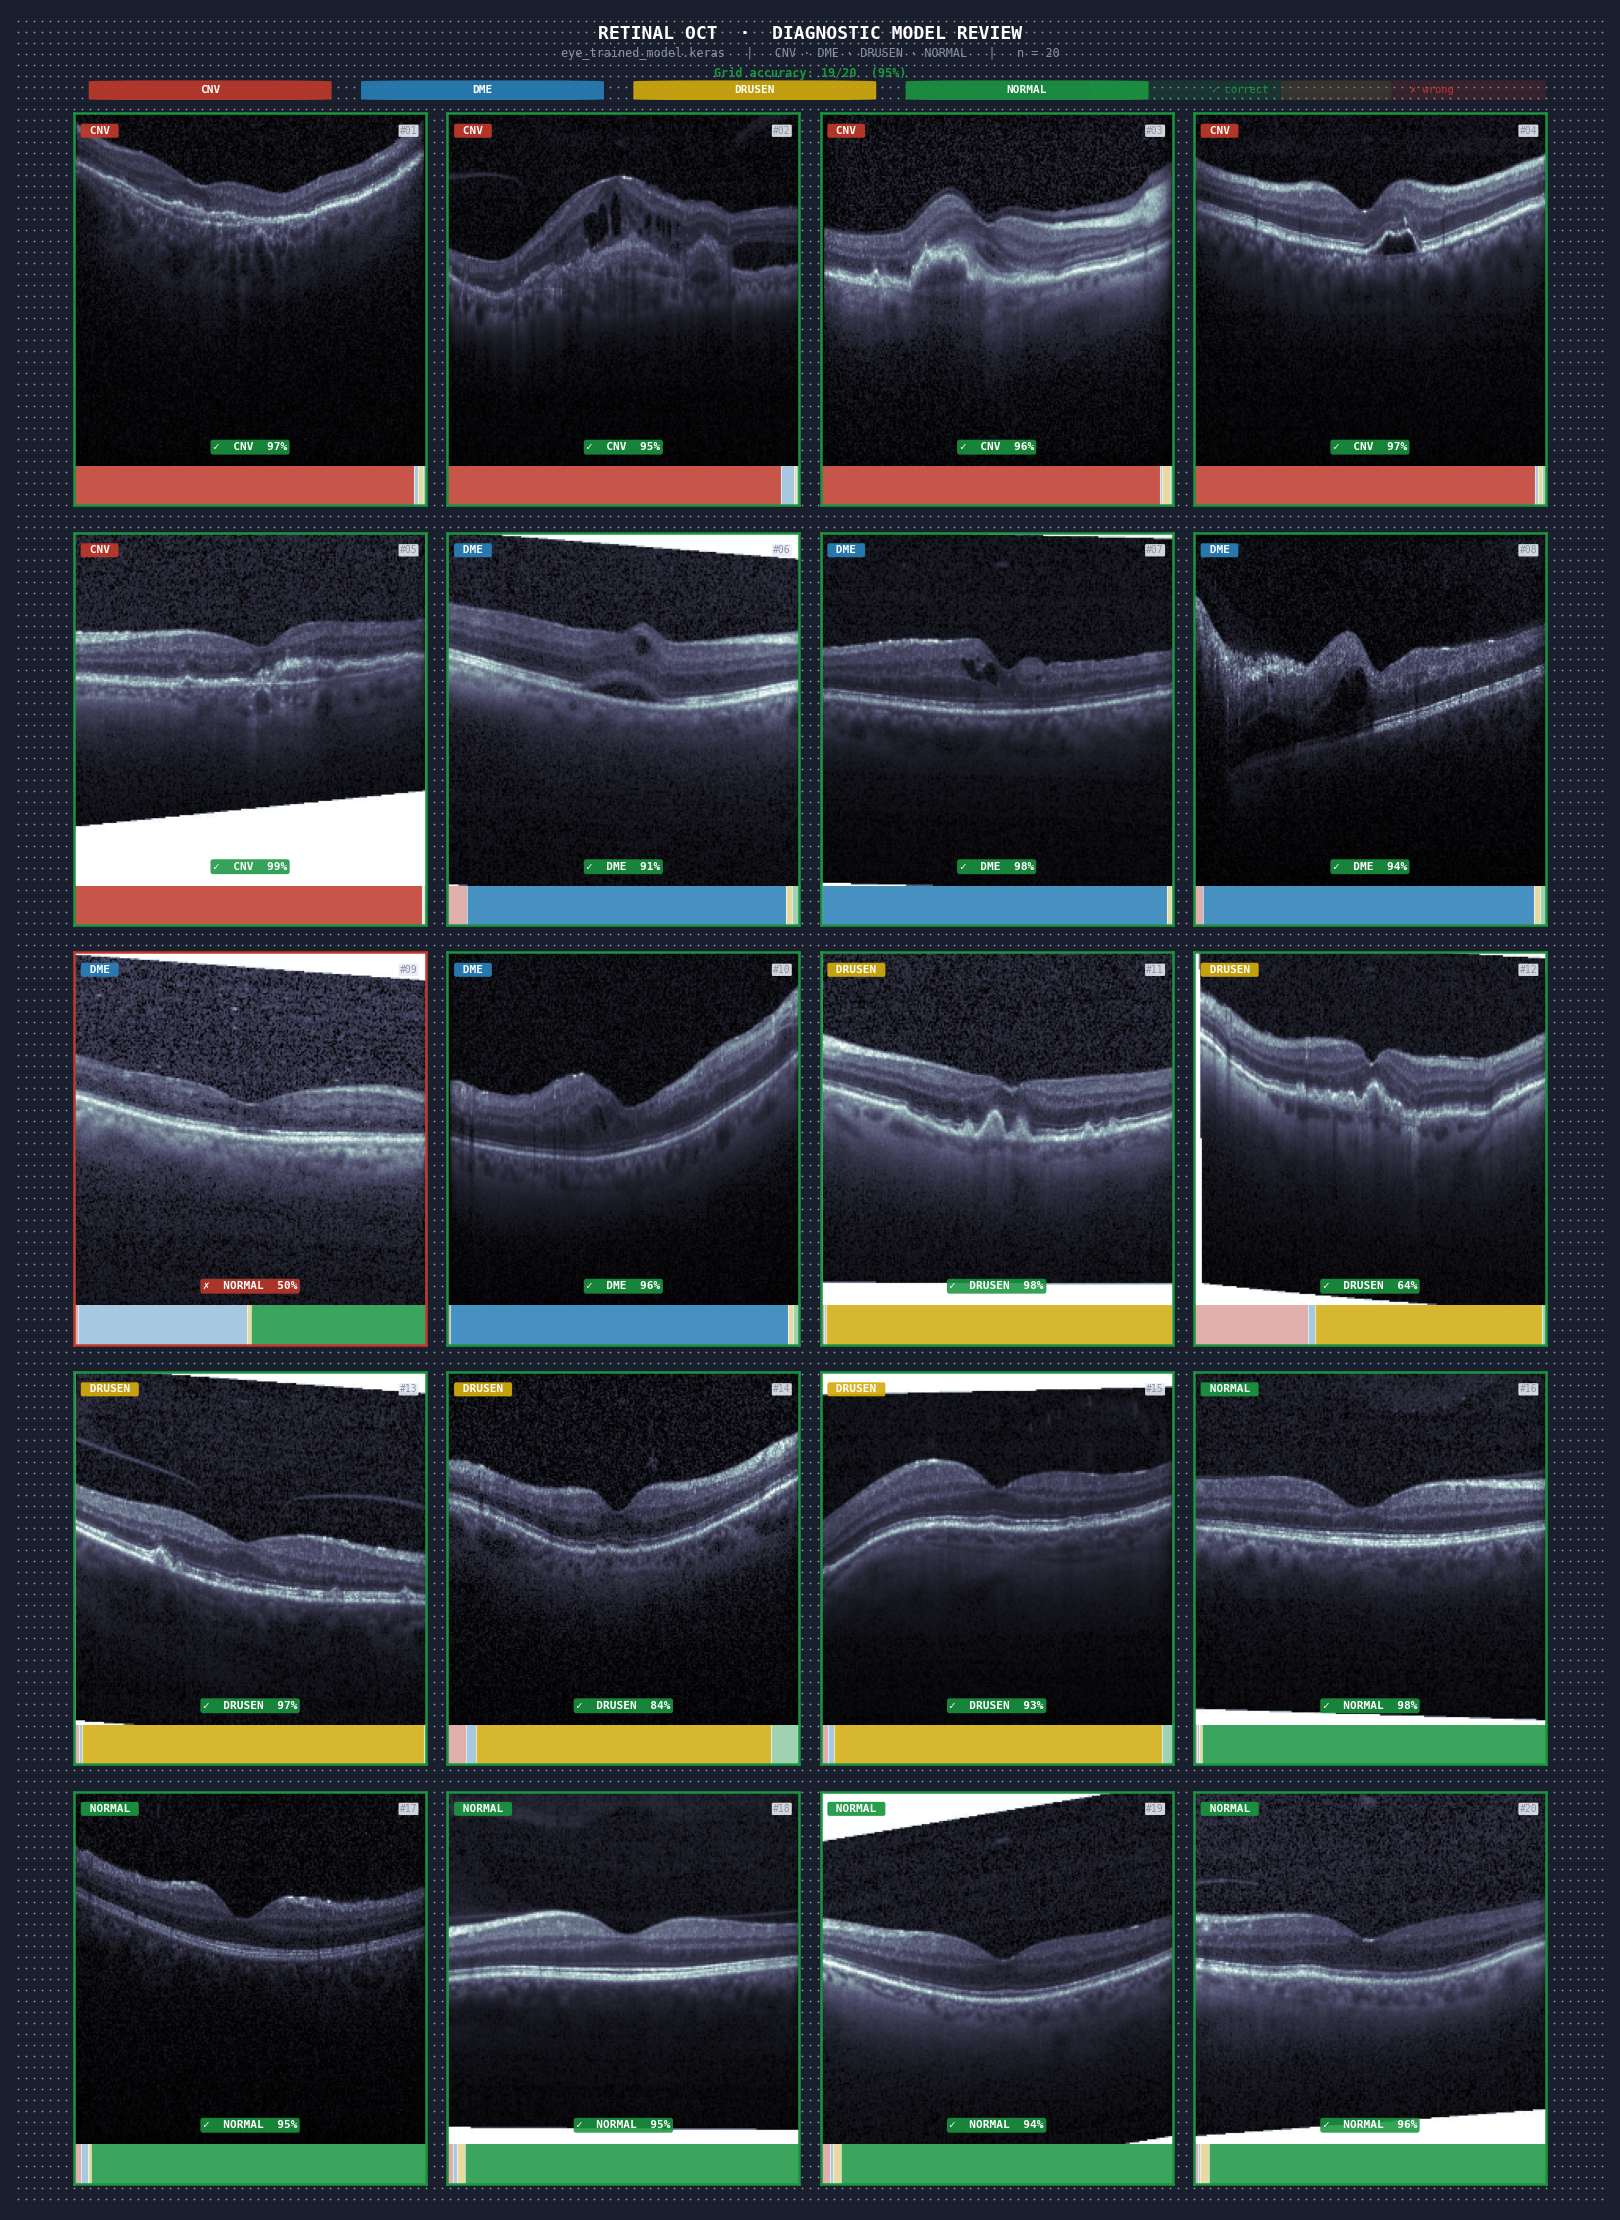

Grid saved → medical_grid_4x4.png  |  Accuracy: 19/20 (95%)


In [ ]:
# - Auto-discover 3 real files per class ─────────────────────────────────────
import glob, random

random.seed(32)
N_PER_CLASS = 5

def sample_files(cls, n):
    all_files = sorted(
        glob.glob(f"{TEST_DIR}/{cls}/*.jpeg") +
        glob.glob(f"{TEST_DIR}/{cls}/*.jpg") +
        glob.glob(f"{TEST_DIR}/{cls}/*.png")
    )
    if len(all_files) < n:
        raise FileNotFoundError(f"Only {len(all_files)} files for {cls}, need {n}")
    return random.sample(all_files, n)

SAMPLE_PATHS = []
TRUE_LABELS  = []
for cls in ["CNV", "DME", "DRUSEN", "NORMAL"]:
    files = sample_files(cls, N_PER_CLASS)
    SAMPLE_PATHS += files
    TRUE_LABELS  += [cls] * N_PER_CLASS

print(f"Loaded {len(SAMPLE_PATHS)} sample paths")
print("Label distribution:", {c: TRUE_LABELS.count(c) for c in class_names})

# - Colour palette ─────────────────────────────────────────────────────────────
CLASS_COLORS = {
    "CNV":    "#C0392B",
    "DME":    "#2980B9",
    "DRUSEN": "#D4AC0D",
    "NORMAL": "#1A9641",
}
BG_COLOR    = "#1A1F2E"
PANEL_COLOR = "#F4F6FA"
TEXT_COLOR  = "#FFFFFF"
MUTED_COLOR = "#8892A4"
CORRECT_CLR = "#1A9641"
WRONG_CLR   = "#C0392B"


def predict_image_grid(path):
    img_gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img_gray is None:
        raise FileNotFoundError(f"Could not read: {path}")
    img_resized = cv2.resize(img_gray, IMG_SIZE)
    inp = img_resized[np.newaxis, :, :, np.newaxis].astype(np.float32)
    probs = model.predict(inp, verbose=0)[0]
    return img_resized, probs, class_names[int(np.argmax(probs))]


results = [predict_image_grid(p) for p in SAMPLE_PATHS]

# - Figure ────────────────────────────────────────────────────────────────────
ROWS, COLS = 5, 4
N          = ROWS * COLS   # 16

fig = plt.figure(figsize=(16, 22), facecolor=BG_COLOR)
fig.patch.set_facecolor(BG_COLOR)

# - Dot-grid background ───────────────────────────────────────────────────────
_bg = fig.add_axes([0, 0, 1, 1], zorder=0)
_bg.set_xlim(0, 1); _bg.set_ylim(0, 1)
_bg.axis("off"); _bg.set_facecolor(BG_COLOR)
_sp = 0.005
_gx, _gy = np.meshgrid(np.arange(_sp, 1.0, _sp), np.arange(_sp, 1.0, _sp))
_bg.scatter(_gx.ravel(), _gy.ravel(), s=1.6, color="#C6D2E8",
            alpha=0.70, zorder=0, linewidths=0)

# - Header ────────────────────────────────────────────────────────────────────
fig.text(0.5, 0.993,
         "RETINAL OCT  ·  DIAGNOSTIC MODEL REVIEW",
         ha="center", va="top", fontsize=13, fontweight="bold",
         color=TEXT_COLOR, fontfamily="monospace")
fig.text(0.5, 0.983,
         f"eye_trained_model.keras   |   CNV · DME · DRUSEN · NORMAL   |   n = {N}",
         ha="center", va="top", fontsize=8.5, color=MUTED_COLOR,
         fontfamily="monospace")

correct_all = sum(1 for i in range(N) if results[i][2] == TRUE_LABELS[i])
acc_col = CORRECT_CLR if correct_all / N >= 0.8 else WRONG_CLR
fig.text(0.5, 0.974,
         f"Grid accuracy: {correct_all}/{N}  ({correct_all/N*100:.0f}%)",
         ha="center", va="top", fontsize=8.5, color=acc_col,
         fontfamily="monospace", fontweight="bold")

# - Legend ────────────────────────────────────────────────────────────────────
leg = fig.add_axes([0.04, 0.959, 0.92, 0.009])
leg.set_xlim(0, 1); leg.set_ylim(0, 1)
leg.axis("off"); leg.patch.set_alpha(0)
for i, cn in enumerate(class_names):
    x = 0.06 + i * 0.185
    leg.add_patch(FancyBboxPatch((x, 0.05), 0.065, 0.9,
                                  boxstyle="round,pad=0.05",
                                  facecolor=CLASS_COLORS[cn], edgecolor="none", alpha=0.9))
    leg.text(x + 0.0325, 0.52, cn, ha="center", va="center",
             fontsize=8, fontweight="bold", color="white", fontfamily="monospace")
for j, (lbl, clr) in enumerate([("✓ correct", CORRECT_CLR), ("✗ wrong", WRONG_CLR)]):
    x = 0.74 + j * 0.13
    leg.add_patch(FancyBboxPatch((x, 0.05), 0.105, 0.9,
                                  boxstyle="round,pad=0.05",
                                  facecolor=clr, edgecolor="none", alpha=0.18))
    leg.text(x + 0.0525, 0.52, lbl, ha="center", va="center",
             fontsize=7.5, color=clr, fontfamily="monospace")

# - Main grid ─────────────────────────────────────────────────────────────────
outer = gridspec.GridSpec(
    ROWS, COLS, figure=fig,
    left=0.04, right=0.96, top=0.953, bottom=0.012,
    hspace=0.07, wspace=0.06,
)

for idx in range(N):
    row, col = divmod(idx, COLS)
    img_gray, probs, pred_label = results[idx]
    true_label = TRUE_LABELS[idx]
    is_correct = pred_label == true_label
    accent     = CORRECT_CLR if is_correct else WRONG_CLR
    check      = "✓" if is_correct else "✗"
    pred_conf  = probs[class_names.index(pred_label)] * 100

    # Each cell: image (tall) + thin bar strip (flush below, no gap)
    inner = gridspec.GridSpecFromSubplotSpec(
        2, 1, subplot_spec=outer[row, col],
        height_ratios=[9, 1],   # bar strip is ~10% of cell height — thin strip only
        hspace=0,               # zero gap — bars flush against image bottom
    )

    # - Image ─────────────────────────────────────────────────────────────────
    ax_img = fig.add_subplot(inner[0])
    ax_img.imshow(img_gray, cmap="bone", vmin=0, vmax=255, aspect="auto")
    ax_img.set_xticks([]); ax_img.set_yticks([])
    for side, sp in ax_img.spines.items():
        if side == "bottom":
            sp.set_visible(False)   # bar strip provides bottom edge
        else:
            sp.set_edgecolor(accent)
            sp.set_linewidth(1.8)
    ax_img.set_facecolor(PANEL_COLOR)

    # True-label badge – top left
    ax_img.text(0.025, 0.965, f" {true_label} ",
                transform=ax_img.transAxes, ha="left", va="top",
                fontsize=8, fontweight="bold", color="white",
                fontfamily="monospace",
                bbox=dict(facecolor=CLASS_COLORS[true_label],
                          edgecolor="none", boxstyle="round,pad=0.18", alpha=0.93))

    # Sample index – top right
    ax_img.text(0.975, 0.965, f"#{idx+1:02d}",
                transform=ax_img.transAxes, ha="right", va="top",
                fontsize=7, color=MUTED_COLOR, fontfamily="monospace",
                bbox=dict(facecolor="#E8ECF3", edgecolor="none",
                          boxstyle="round,pad=0.12", alpha=0.90))

    # Prediction overlay – bottom centre
    ax_img.text(0.5, 0.04,
                f"{check}  {pred_label}  {pred_conf:.0f}%",
                transform=ax_img.transAxes, ha="center", va="bottom",
                fontsize=8, fontweight="bold", color="white",
                fontfamily="monospace",
                bbox=dict(facecolor=accent, edgecolor="none",
                          boxstyle="round,pad=0.22", alpha=0.88))

    # - Bar strip — no labels, just 4 colour blocks proportional to probability
    ax_bar = fig.add_subplot(inner[1])
    ax_bar.set_facecolor(PANEL_COLOR)
    for side, sp in ax_bar.spines.items():
        if side == "top":
            sp.set_visible(False)
        else:
            sp.set_edgecolor(accent)
            sp.set_linewidth(1.8)
    ax_bar.set_xticks([]); ax_bar.set_yticks([])
    ax_bar.tick_params(left=False, bottom=False)

    # Draw 4 horizontal segments filling the full width — widths ∝ probability
    x_cursor = 0.0
    for cn in class_names:
        p = float(probs[class_names.index(cn)])
        ax_bar.barh(
            0, p * 100, left=x_cursor * 100,
            color=CLASS_COLORS[cn],
            height=1.0, edgecolor="none",
            alpha=0.85 if cn == pred_label else 0.38,
        )
        x_cursor += p

    # Thin white dividers between segments for readability
    cumulative = 0.0
    for cn in class_names[:-1]:
        cumulative += float(probs[class_names.index(cn)])
        ax_bar.axvline(x=cumulative * 100, color="white",
                       linewidth=0.8, alpha=0.6)

    ax_bar.set_xlim(0, 100)
    ax_bar.set_ylim(-0.5, 0.5)
    ax_bar.set_facecolor(PANEL_COLOR)

plt.savefig("medical_grid_4x4.png", dpi=300, bbox_inches="tight",
            facecolor=BG_COLOR, edgecolor="none")
plt.show()
print(f"Grid saved → medical_grid_4x4.png  |  Accuracy: {correct_all}/{N} ({correct_all/N*100:.0f}%)")


In [8]:
# Uncomment to save outputs to Google Drive
# OUTPUT_DIR = Path("/content/drive/MyDrive/oct_outputs_cnn")
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
#
# cm_df.to_csv(OUTPUT_DIR / "confusion_matrix.csv")
# adv_df.to_csv(OUTPUT_DIR / "advanced_metrics_per_class.csv", index=False)
# metrics_df.to_csv(OUTPUT_DIR / "split_metrics.csv", index=False)
# np.save(str(OUTPUT_DIR / "y_pred_proba.npy"), y_pred_proba)
# np.save(str(OUTPUT_DIR / "y_true.npy"), y_true)
# np.save(str(OUTPUT_DIR / "y_pred.npy"), y_pred)
# print("Results saved to", OUTPUT_DIR)
print("Uncomment the block above to save results to Google Drive.")


Uncomment the block above to save results to Google Drive.
